In [65]:
import polars as pl
import matplotlib.pyplot as plt
import numpy as np

In [66]:

# read data from dataset/raw/Acacia confusa/
df_C = pl.read_csv("../../dataset/raw/Acacia confusa/20250923-Acacia confusa-1-C-1.txt", separator=";", has_header=False)
df_R = pl.read_csv("../../dataset/raw/Acacia confusa/20250923-Acacia confusa-1-R-1.txt", separator=";", has_header=False)
df_T = pl.read_csv("../../dataset/raw/Acacia confusa/20250923-Acacia confusa-1-T-1.txt", separator=";", has_header=False)

In [67]:
# Process each dataframe (clean and rename columns)
def process_raman_data(df: pl.DataFrame, facet_name: str) -> pl.DataFrame:
    """Process Raman spectral data and baseline-correct negative intensities"""

    # Drop third column (all zeros) and rename
    df_processed = df.drop("column_3").rename({
        "column_1": "wavenumber",
        "column_2": "intensity"
    })

    # Compute intensity minimum once
    intensity_min = df_processed["intensity"].min()

    # Add facet identifier and baseline-shifted intensity
    df_processed = df_processed.with_columns([
        pl.when(intensity_min < 0)
          .then(pl.col("intensity") - intensity_min)
          .otherwise(pl.col("intensity"))
          .alias("intensity_shifted"),
        pl.lit(facet_name).alias("facet")
    ])
    return df_processed

# Process all three facets
df_C_processed = process_raman_data(df_C, "Cross")
df_R_processed = process_raman_data(df_R, "Radial")
df_T_processed = process_raman_data(df_T, "Tangential")

In [68]:
df_C_processed

wavenumber,intensity,intensity_shifted,facet
f64,f64,f64,str
98.64605,0.0,867.702942,"""Cross"""
101.2353,0.0,867.702942,"""Cross"""
103.8217,0.0,867.702942,"""Cross"""
106.4096,13.755555,881.458497,"""Cross"""
108.9945,-9.306666,858.396276,"""Cross"""
…,…,…,…
3505.699,-33.37537,834.327572,"""Cross"""
3506.716,30.846828,898.54977,"""Cross"""
3507.729,-38.478634,829.224308,"""Cross"""


/var/folders/16/k68ffsrj7v9cpcxbn3mv05640000gn/T/ipykernel_78632/295172707.py:27: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  plt.tight_layout()
/Users/schwinger42/PycharmProjects/wood_identification/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


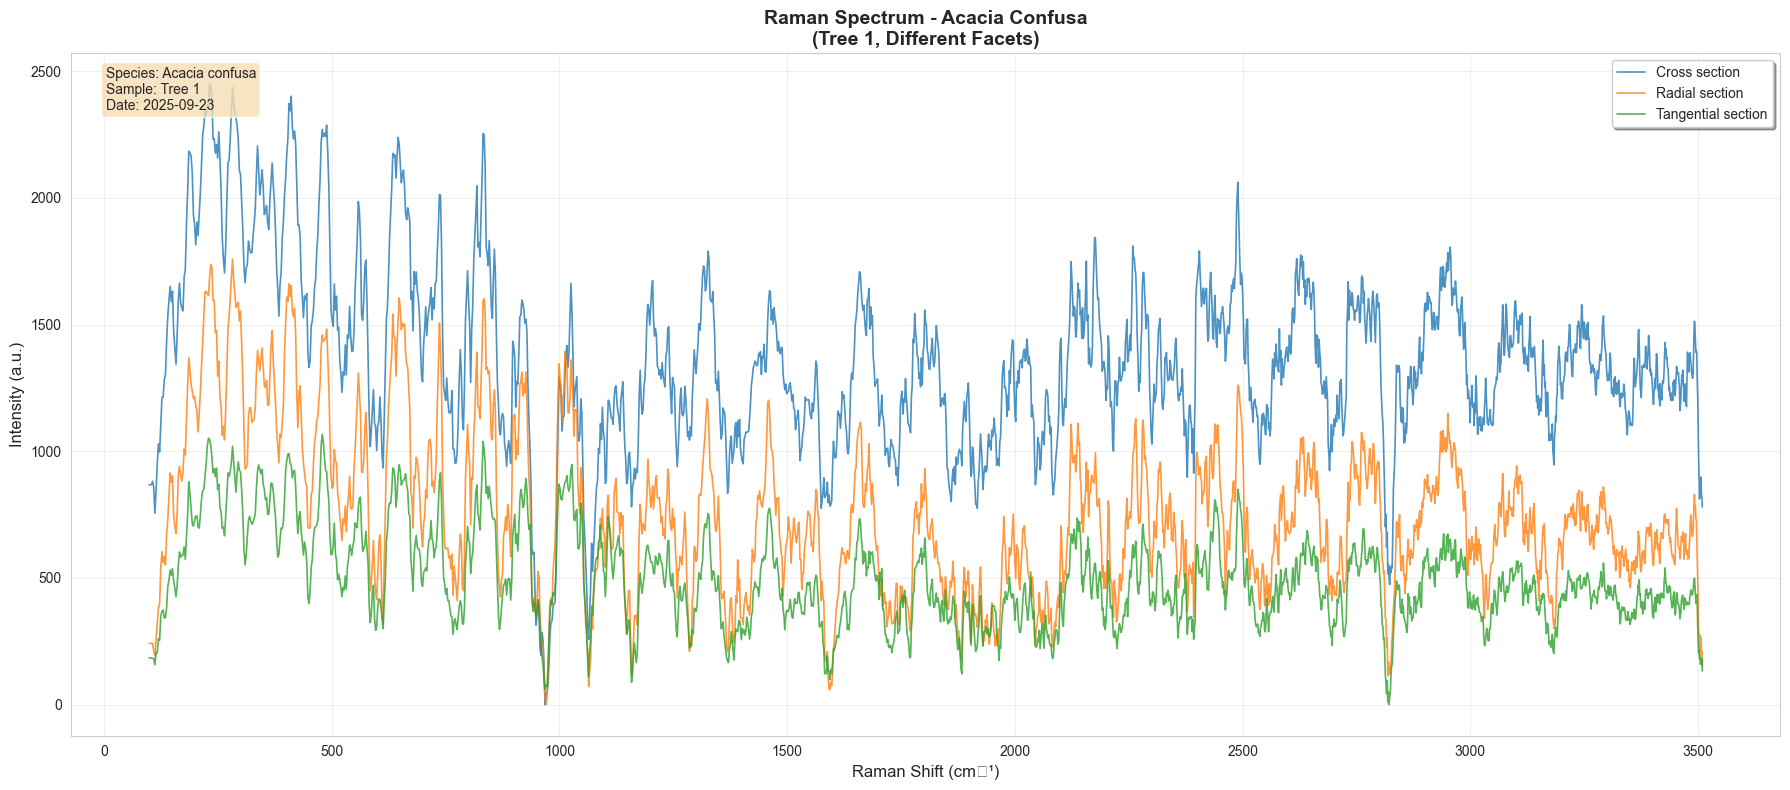

In [69]:
# Create publication-quality Raman spectrum plot
plt.figure(figsize=(18, 8))

# Plot all three facets
plt.plot(df_C_processed["wavenumber"], df_C_processed["intensity_shifted"],
         label="Cross section", color='#1f77b4', linewidth=1.2, alpha=0.8)
plt.plot(df_R_processed["wavenumber"], df_R_processed["intensity_shifted"],
         label="Radial section", color='#ff7f0e', linewidth=1.2, alpha=0.8)
plt.plot(df_T_processed["wavenumber"], df_T_processed["intensity_shifted"],
         label="Tangential section", color='#2ca02c', linewidth=1.2, alpha=0.8)

# Format plot with spectroscopy standards
plt.xlabel('Raman Shift (cm⁻¹)', fontsize=12)
plt.ylabel('Intensity (a.u.)', fontsize=12)
plt.title('Raman Spectrum - Acacia Confusa\n(Tree 1, Different Facets)', fontsize=14, fontweight='bold')
plt.legend(frameon=True, fancybox=True, shadow=True)
plt.grid(True, alpha=0.3)

# # Invert x-axis (spectroscopy convention)
# plt.gca().invert_xaxis()

# Add sample information
plt.text(0.02, 0.98, 'Species: Acacia confusa\nSample: Tree 1\nDate: 2025-09-23',
         transform=plt.gca().transAxes, verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

plt.tight_layout()
plt.show()

/var/folders/16/k68ffsrj7v9cpcxbn3mv05640000gn/T/ipykernel_78632/1642701539.py:22: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  plt.tight_layout()


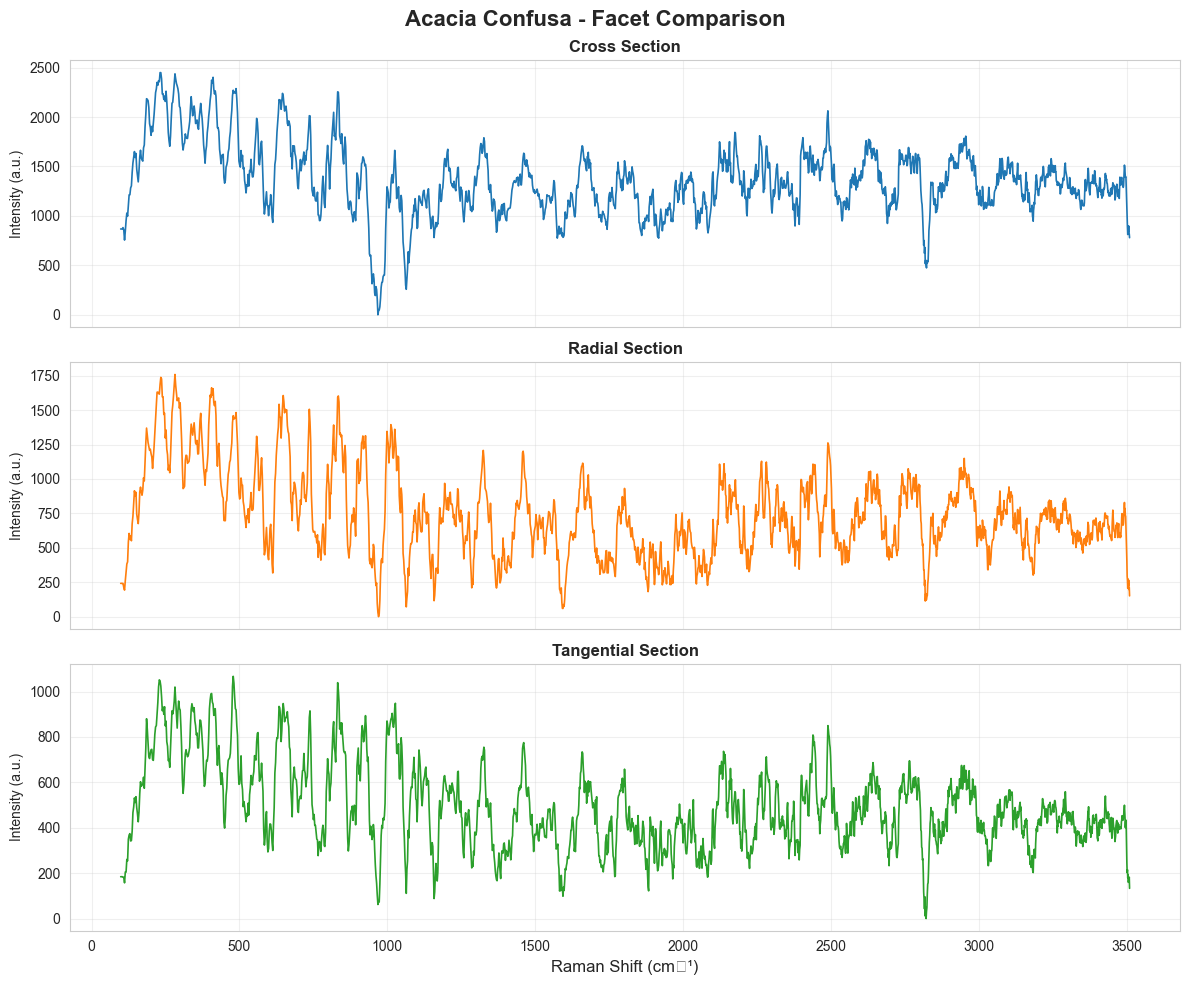

In [70]:
# Individual subplot view for detailed comparison
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# Plot each facet in separate subplot
facets_data = [
    (df_C_processed, "Cross Section", '#1f77b4'),
    (df_R_processed, "Radial Section", '#ff7f0e'),
    (df_T_processed, "Tangential Section", '#2ca02c')
]

for i, (df, title, color) in enumerate(facets_data):
    axes[i].plot(df["wavenumber"], df["intensity_shifted"],
                label=f"Facet {i+1}",
                color=color, linewidth=1.2)
    axes[i].set_title(title, fontweight='bold')
    axes[i].set_ylabel('Intensity (a.u.)')
    axes[i].grid(True, alpha=0.3)
    # axes[i].invert_xaxis()

axes[2].set_xlabel('Raman Shift (cm⁻¹)', fontsize=12)
plt.suptitle('Acacia Confusa - Facet Comparison', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

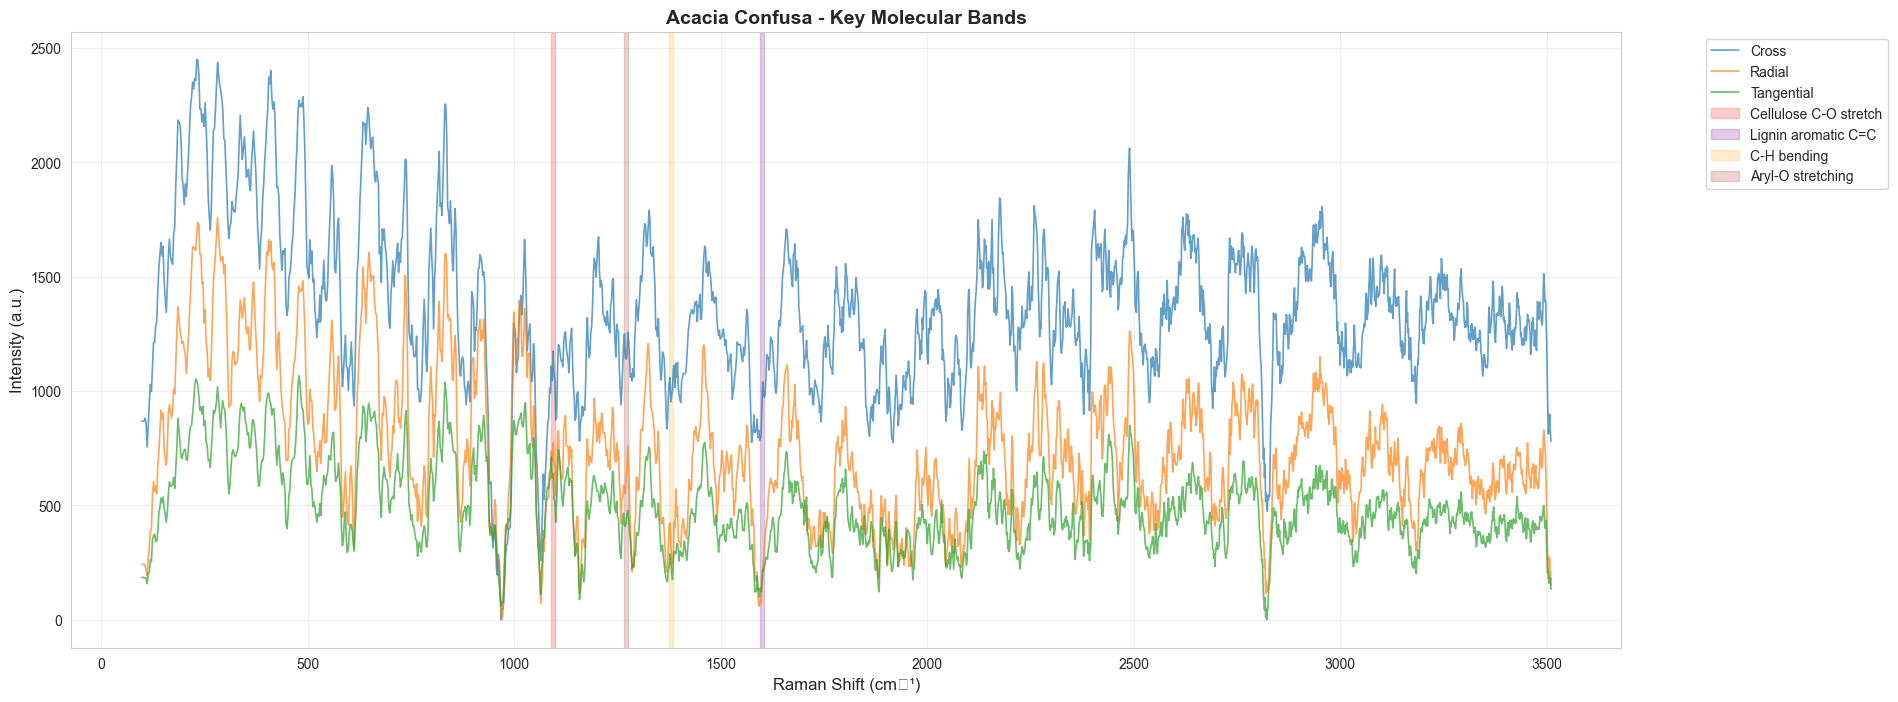

=== Raman Spectral Data Summary ===

Cross Facet:
  Wavenumber range: 98.6 - 3509.8 cm⁻¹
  Intensity range: -867.7 - 1581.6
  Mean intensity: 478.0
  Data points: 2005

Radial Facet:
  Wavenumber range: 98.6 - 3509.8 cm⁻¹
  Intensity range: -241.7 - 1516.9
  Mean intensity: 481.9
  Data points: 2005

Tangential Facet:
  Wavenumber range: 98.6 - 3509.8 cm⁻¹
  Intensity range: -184.2 - 882.7
  Mean intensity: 294.1
  Data points: 2005


In [71]:
# Highlight key molecular regions for wood analysis
plt.figure(figsize=(20, 8))

# Plot all spectra
plt.plot(df_C_processed["wavenumber"], df_C_processed["intensity_shifted"],
         label="Cross", alpha=0.7, linewidth=1.2)
plt.plot(df_R_processed["wavenumber"], df_R_processed["intensity_shifted"],
         label="Radial", alpha=0.7, linewidth=1.2)
plt.plot(df_T_processed["wavenumber"], df_T_processed["intensity_shifted"],
         label="Tangential", alpha=0.7, linewidth=1.2)

# Highlight important molecular bands for wood identification
molecular_bands = {
    'Cellulose C-O stretch': (1090, 1100),
    'Lignin aromatic C=C': (1595, 1605),
    'C-H bending': (1375, 1385),
    'Aryl-O stretching': (1265, 1275)
}

colors = ['red', 'purple', 'orange', 'brown']
for i, (band_name, (low, high)) in enumerate(molecular_bands.items()):
    plt.axvspan(low, high, alpha=0.2, color=colors[i], label=band_name)

plt.xlabel('Raman Shift (cm⁻¹)', fontsize=12)
plt.ylabel('Intensity (a.u.)', fontsize=12)
plt.title('Acacia Confusa - Key Molecular Bands', fontsize=14, fontweight='bold')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
# plt.gca().invert_xaxis()
# plt.tight_layout()
plt.show()

# Data summary statistics
print("=== Raman Spectral Data Summary ===")
for name, df in [("Cross", df_C_processed), ("Radial", df_R_processed), ("Tangential", df_T_processed)]:
    print(f"\n{name} Facet:")
    print(f"  Wavenumber range: {df['wavenumber'].min():.1f} - {df['wavenumber'].max():.1f} cm⁻¹")
    print(f"  Intensity range: {df['intensity'].min():.1f} - {df['intensity'].max():.1f}")
    print(f"  Mean intensity: {df['intensity'].mean():.1f}")
    print(f"  Data points: {len(df)}")

In [72]:
# Combine all data for further analysis
df_combined = pl.concat([df_C_processed, df_R_processed, df_T_processed])
print(f"\nCombined dataset shape: {df_combined.shape}")
print(f"Facets: {df_combined['facet'].unique().to_list()}")


Combined dataset shape: (6015, 4)
Facets: ['Cross', 'Radial', 'Tangential']


In [73]:
# exec(open("../../src/clean_organized_dataset.py").read())

In [74]:
import pandas as pd
import numpy as np

# Load your reality
metadata_path = '/Users/schwinger42/PycharmProjects/wood_identification/dataset/organized/dataset_metadata.csv'
df = pd.read_csv(metadata_path)

# --- VALIDATION ---

# 1. How many files do you actually have?
print(f"Total spectra in metadata: {len(df)}") # Should be ~1051

# 2. What's the REAL train/test split?
test_species = df[df['split'] == 'test']['species'].unique()
print(f"Species in the pre-defined test set: {test_species}")
# This MUST match Junie_readme.md: ['Swietenia_Marophylla', 'Chamaecyparis_Obtusa_var_Formosana']

# 3. How many unique trees? This is your number of CV folds.
n_trees = df['tree_group'].nunique()
print(f"Number of unique trees for LOGOCV: {n_trees}") # Should be 11

if n_trees != 11:
    print("WARNING: Tree count mismatch. Re-evaluate your grouping strategy immediately.")

Total spectra in metadata: 1050
Species in the pre-defined test set: ['Swietenia_Marophylla' 'Chamaecyparis_Obtusa_var_Formosana']
Number of unique trees for LOGOCV: 11


In [75]:
# Update your imports in the notebook
import numpy as np
from scipy.signal import savgol_filter
from pybaselines.morphological import mor # <-- Import the specific function

def preprocess_spectrum(wavenumbers, intensities):
    """
    Implements the PROVEN preprocessing pipeline from Junie_readme.md.
    1. Savitzky-Golay filtering
    2. Morphological baseline correction (mor)
    3. Robust normalization
    """

    # 1. Savitzky-Golay smoothing (Use the optimized parameters from Junie_readme.md)
    smoothed = savgol_filter(intensities, window_length=15, polyorder=2)

    # 2. Morphological baseline correction using pybaselines
    # The mor function returns the baseline and additional parameters. We only need the corrected signal.
    baseline, _ = mor(smoothed)
    baseline_corrected = smoothed - baseline

    # 3. Robust normalization (Shift to non-negative and scale)
    min_val = np.min(baseline_corrected)
    shifted = baseline_corrected - min_val

    # Normalize by the L2 norm (vector magnitude) to handle intensity variations
    norm = np.linalg.norm(shifted)
    if norm > 0:
        normalized = shifted / norm
    else:
        # Handle the edge case of a zero-vector
        normalized = shifted

    return normalized

# Step 3: Process the Entire Training Dataset


In [76]:
import os
from tqdm import tqdm

# First, get all your training file paths and sort them for consistency
train_dir = '../../dataset/organized/train/'
metadata_train = df[df['split'] == 'train'].copy()

# Make sure the dataframe is sorted the same way we'll read files
metadata_train = metadata_train.sort_values(by='filename').reset_index(drop=True)

# Create file paths from filenames
file_paths = [os.path.join(train_dir, row.species, row.filename) for _, row in metadata_train.iterrows()]

# Now, load and process
X_train_list = []
wavenumbers = None # To store the wavenumber axis from the first file

print("Processing training data...")
for fpath in tqdm(file_paths):
    # Load the spectrum
    data = np.loadtxt(fpath, delimiter=';')

    if wavenumbers is None:
        wavenumbers = data[:, 0]

    intensities = data[:, 1]

    # Apply your battle-tested preprocessing function
    processed_intensities = preprocess_spectrum(wavenumbers, intensities)
    X_train_list.append(processed_intensities)

# Create the final training matrix and target vector
X_train = np.array(X_train_list)
y_train = metadata_train['species']
cube_groups_train = metadata_train['cube_group']
groups_train = metadata_train['tree_group']

print(f"Original number of trees in training: {metadata_train['tree_group'].nunique()}")
print(f"New number of cubes for LOGOCV: {cube_groups_train.nunique()}")

print(f"Successfully created training matrix X_train with shape: {X_train.shape}")
print(f"Target vector y_train has shape: {y_train.shape}")
print(f"Groups vector for CV has shape: {cube_groups_train.shape}")

Processing training data...


100%|██████████| 870/870 [00:04<00:00, 182.35it/s]

Original number of trees in training: 9
New number of cubes for LOGOCV: 28
Successfully created training matrix X_train with shape: (870, 2005)
Target vector y_train has shape: (870,)
Groups vector for CV has shape: (870,)


# Phase 3: Modeling & Validation (Hour 3 - 6)
## Step 1: Build the Classifier



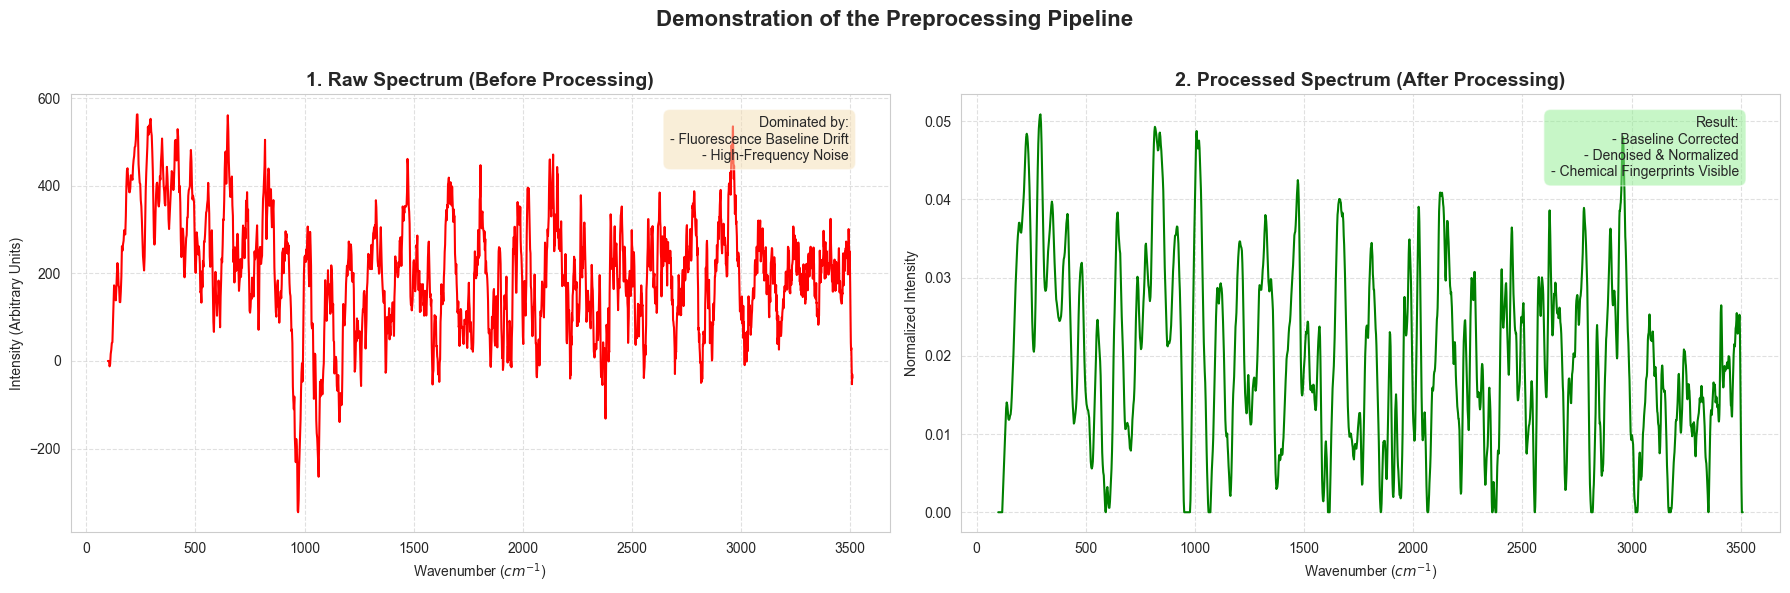

In [77]:
import matplotlib.pyplot as plt
import numpy as np
import os

# --- Visualization of Preprocessing ---

# Pick one representative raw spectrum to demonstrate the pipeline
# We'll use the same file you tested the predict.py script with
example_file = '../../dataset/organized/test/Swietenia_Marophylla/24mW-20250926-Swietenia_Marophylla-2-1-C-9.txt'

# Load raw data
raw_data = np.loadtxt(example_file, delimiter=';')
raw_wavenumbers = raw_data[:, 0]
raw_intensities = raw_data[:, 1]

# Process the data using your function
processed_intensities = preprocess_spectrum(raw_wavenumbers, raw_intensities)

# Create the comparison plot
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Plot 1: Raw Spectrum
axes[0].plot(raw_wavenumbers, raw_intensities, color='red')
axes[0].set_title('1. Raw Spectrum (Before Processing)', fontsize=14, weight='bold')
axes[0].set_xlabel('Wavenumber ($cm^{-1}$)')
axes[0].set_ylabel('Intensity (Arbitrary Units)')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].text(0.95, 0.95, 'Dominated by:\n- Fluorescence Baseline Drift\n- High-Frequency Noise',
             transform=axes[0].transAxes, ha='right', va='top', bbox=dict(boxstyle='round,pad=0.5', fc='wheat', alpha=0.5))


# Plot 2: Processed Spectrum
axes[1].plot(wavenumbers, processed_intensities, color='green')
axes[1].set_title('2. Processed Spectrum (After Processing)', fontsize=14, weight='bold')
axes[1].set_xlabel('Wavenumber ($cm^{-1}$)')
axes[1].set_ylabel('Normalized Intensity')
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].text(0.95, 0.95, 'Result:\n- Baseline Corrected\n- Denoised & Normalized\n- Chemical Fingerprints Visible',
             transform=axes[1].transAxes, ha='right', va='top', bbox=dict(boxstyle='round,pad=0.5', fc='lightgreen', alpha=0.5))


plt.suptitle('Demonstration of the Preprocessing Pipeline', fontsize=16, weight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [78]:
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder
import xgboost as xgb

# Encode your string labels into integers
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)

# 1. Define the individual models (use proven parameters from Junie_readme.md)
xgb_clf = xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1, eval_metric='mlogloss')
rf_clf = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, n_jobs=-1)
svm_clf = SVC(kernel='rbf', probability=True, random_state=42)

# 2. Create the Voting Ensemble
ensemble_clf = VotingClassifier(
    estimators=[('xgb', xgb_clf), ('rf', rf_clf), ('svm', svm_clf)],
    voting='soft'
)

## Step 2: Run the Leave-One-Group-Out Cross-Validation (LOGOCV)



In [79]:
from sklearn.model_selection import LeaveOneGroupOut, cross_val_score

# Initialize the LOGOCV splitter
logo = LeaveOneGroupOut()

print("Running Leave-One-CUBE-Out Cross-Validation...")

# Use the new cube-level groups
cv_scores = cross_val_score(
    ensemble_clf,
    X_train,
    y_train_encoded,
    cv=logo,
    groups=cube_groups_train, # <-- USE THE CUBE GROUPS
    n_jobs=-1,
    scoring='accuracy'
)

print(f"LOGOCV complete.")
print(f"Number of CV scores (cubes): {len(cv_scores)}")
print(f"Mean CV Accuracy: {np.mean(cv_scores):.4f} ± {np.std(cv_scores):.4f}")

# Sanity Check
if np.mean(cv_scores) == 0.0:
    print("❌ Still zero accuracy. There is a deeper data alignment or preprocessing issue.")
elif np.mean(cv_scores) > 0.95:
    print("⚠️ WARNING: Accuracy is suspiciously high. Double-check for data leakage.")
else:
    print("✅ Validation successful. This is a much more realistic performance estimate.")

Running Leave-One-CUBE-Out Cross-Validation...
LOGOCV complete.
Number of CV scores (cubes): 28
Mean CV Accuracy: 0.8552 ± 0.1845
✅ Validation successful. This is a much more realistic performance estimate.


In [80]:
# In a new cell in your notebook

print("Training the final ensemble model on all 870 training samples...")
# We use the same classifier definition from before
ensemble_clf.fit(X_train, y_train_encoded)
print("Final model training complete.")

# Also, train the XGBoost model separately for the SHAP analysis later
print("Training a standalone XGBoost model for explainability...")
xgb_clf.fit(X_train, y_train_encoded)
print("XGBoost model training complete.")

Training the final ensemble model on all 870 training samples...
Final model training complete.
Training a standalone XGBoost model for explainability...
XGBoost model training complete.


In [81]:
# Filter the metadata for the test set
metadata_test = df[df['split'] == 'test'].copy().sort_values(by='filename').reset_index(drop=True)

# Get the file paths
test_dir = '../../dataset/organized/test/'
test_paths = [os.path.join(test_dir, row.species, row.filename) for _, row in metadata_test.iterrows()]

# Process the test files
X_test_list = []
print("Processing test data...")
for fpath in tqdm(test_paths):
    data = np.loadtxt(fpath, delimiter=';')
    # Use the same wavenumbers from the training data
    intensities = data[:, 1]
    processed = preprocess_spectrum(wavenumbers, intensities)
    X_test_list.append(processed)

# Create the final test matrix and target vector
X_test = np.array(X_test_list)
y_test = metadata_test['species']
y_test_encoded = le.transform(y_test) # Use the SAME encoder from training

print(f"Successfully created test matrix X_test with shape: {X_test.shape}")

Processing test data...


100%|██████████| 180/180 [00:00<00:00, 212.62it/s]

Successfully created test matrix X_test with shape: (180, 2005)


/Users/schwinger42/PycharmProjects/wood_identification/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/schwinger42/PycharmProjects/wood_identification/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/schwinger42/PycharmProjects/wood_identification/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control thi

Evaluating final model on the held-out test set...

Classification Report on Test Set:
                                    precision    recall  f1-score   support

                    Acacia_Mangium       0.00      0.00      0.00         0
         Chamaecyparis_Formosensis       0.00      0.00      0.00         0
Chamaecyparis_Obtusa_var_Formosana       0.98      0.57      0.72        90
                Fokienia_Hodginsii       0.00      0.00      0.00         0
                Swietenia_Mahagoni       0.00      0.00      0.00         0
              Swietenia_Marophylla       0.83      0.56      0.67        90

                          accuracy                           0.56       180
                         macro avg       0.30      0.19      0.23       180
                      weighted avg       0.91      0.56      0.69       180


Confusion Matrix:


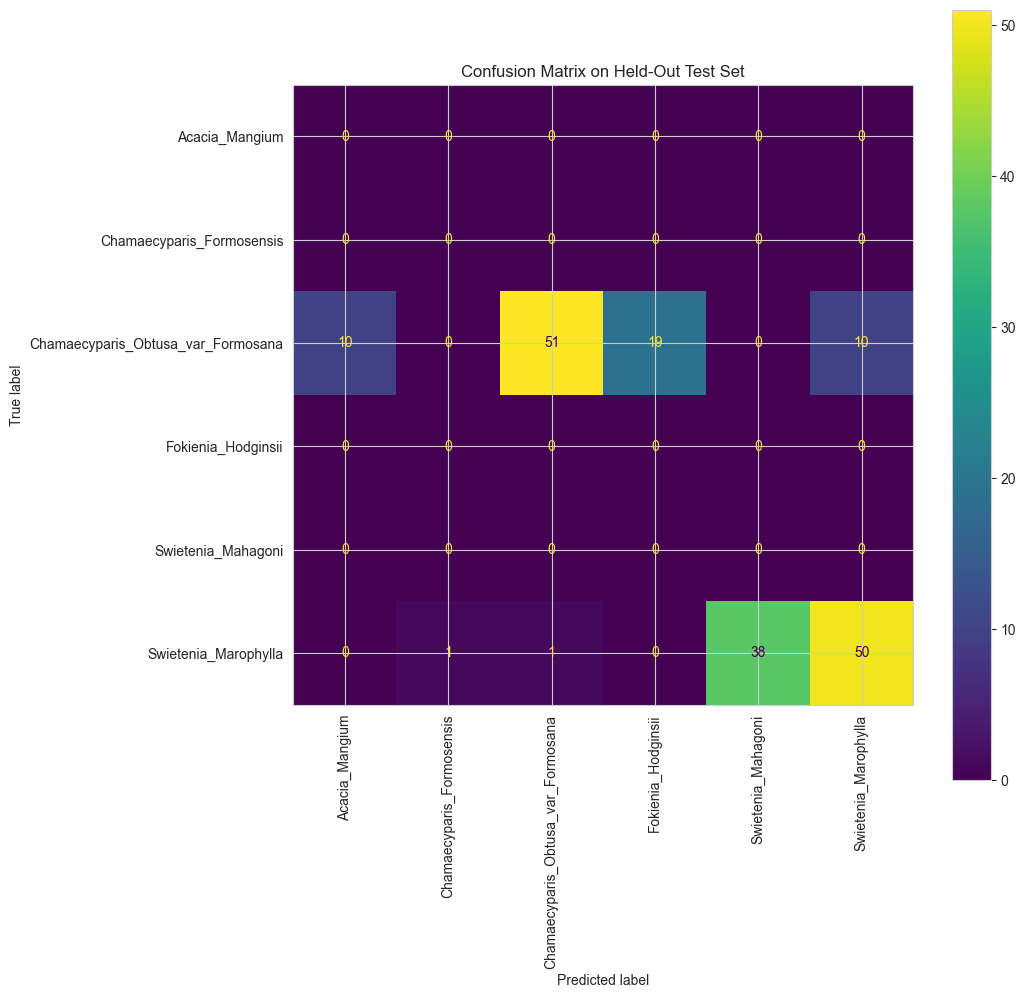

In [82]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("Evaluating final model on the held-out test set...")
y_pred_encoded = ensemble_clf.predict(X_test)
y_pred = le.inverse_transform(y_pred_encoded)

# Print the detailed classification report
print("\nClassification Report on Test Set:")
print(classification_report(y_test, y_pred))

# Visualize the confusion matrix
print("\nConfusion Matrix:")
fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, xticks_rotation='vertical')
plt.title("Confusion Matrix on Held-Out Test Set")
plt.show()

Calculating SHAP values for the XGBoost model...
Generating SHAP summary plot...


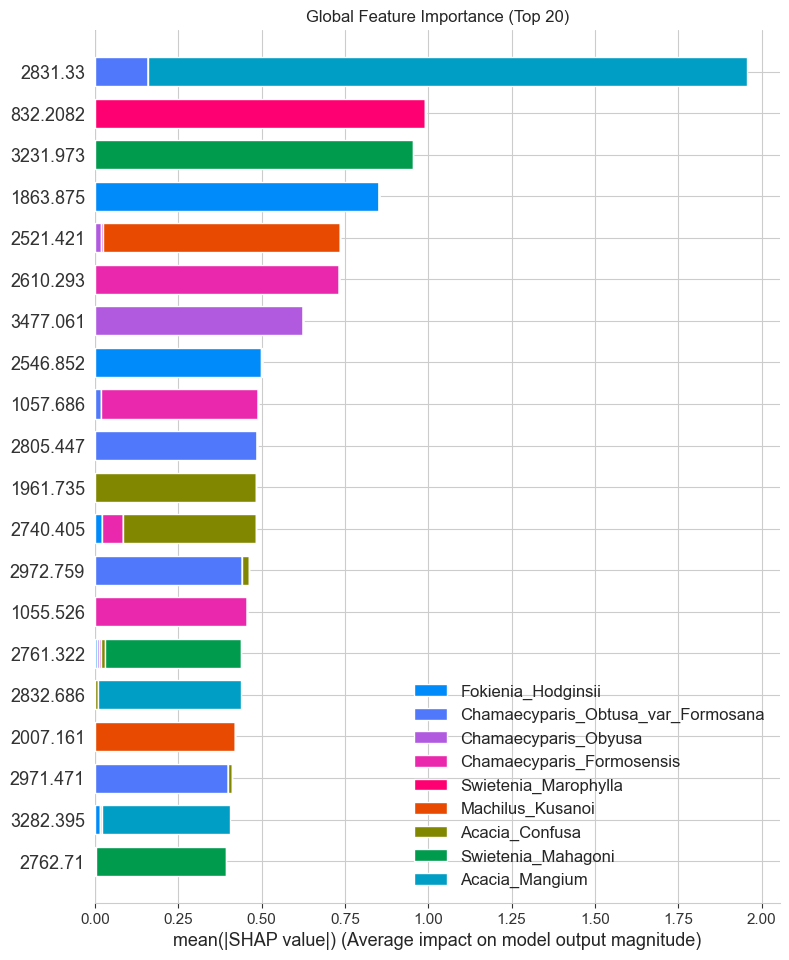

In [83]:
import shap

# IMPORTANT: Restart your kernel after installing shap

print("Calculating SHAP values for the XGBoost model...")
# Use the standalone xgb_clf we trained earlier
explainer = shap.TreeExplainer(xgb_clf)
shap_values = explainer(X_test)

print("Generating SHAP summary plot...")
# Create a mapping from encoded labels back to species names for the plot legend
class_names = le.classes_

# Plot the SHAP summary
plt.figure(figsize=(10,8))
shap.summary_plot(shap_values, X_test, feature_names=wavenumbers, class_names=class_names, plot_type='bar', show=False)
plt.xlabel("mean(|SHAP value|) (Average impact on model output magnitude)")
plt.title("Global Feature Importance (Top 20)")
plt.show()

In [84]:
import os
import pickle

# Define the target directory path relative to the notebook
model_dir = '../../models'

# --- THE FIX: Create the directory if it doesn't exist ---
# The exist_ok=True parameter prevents an error if the directory already exists.
os.makedirs(model_dir, exist_ok=True)
print(f"Directory '{model_dir}' ensured to exist.")

# Now, save the assets into that directory using the defined path
print("Saving assets to disk...")

# Save the trained ensemble model
with open(os.path.join(model_dir, 'wood_classifier_ensemble.pkl'), 'wb') as f:
    pickle.dump(ensemble_clf, f)

# Save the XGBoost model (for SHAP)
with open(os.path.join(model_dir, 'wood_classifier_xgb.pkl'), 'wb') as f:
    pickle.dump(xgb_clf, f)

# Save the label encoder
with open(os.path.join(model_dir, 'label_encoder.pkl'), 'wb') as f:
    pickle.dump(le, f)

# Save the wavenumbers array
with open(os.path.join(model_dir, 'wavenumbers.pkl'), 'wb') as f:
    pickle.dump(wavenumbers, f)

print("Assets successfully saved.")

Directory '../../models' ensured to exist.
Saving assets to disk...
Assets successfully saved.
